In [1]:
# 7.3.2 导入数据并检查基本情况

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 兼容从项目根目录或 notebooks 目录启动
project_root = Path.cwd()
if not (project_root / "data").is_dir():
    project_root = project_root.parent

data_path = project_root / "data/processed/delivery_review_statistical.csv"

df = pd.read_csv(data_path)

print("数据形状：", df.shape)
print("唯一订单数：", df["order_id"].nunique())
print("有效评价订单：", df["avg_review_score"].notna().sum())

# 查看主要数值变量的描述性统计
display(
    df[["delivery_days", "delay_days", "avg_review_score"]]
    .describe()
)

数据形状： (96203, 7)
唯一订单数： 96203
有效评价订单： 95560


,delivery_days,delay_days,avg_review_score
count,96203.000000,96203.000000,95560.000000
mean,12.538461,-11.807969,4.156579
std,9.530142,10.088942,1.283182
min,0.533400,-147.000000,1.000000
25%,6.756700,-17.000000,4.000000
50%,10.210000,-12.000000,5.000000
75%,15.682650,-7.000000,5.000000
max,209.628600,188.000000,5.000000


In [2]:
# =========================================================
# 7.3.3 配送时间与延迟天数的描述性统计
# =========================================================

# 1. 实际配送时间分布
# 目的：分析配送时长的集中趋势、离散程度和长尾情况

delivery_stats = df["delivery_days"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("=== 实际配送时间统计（天）===")
print(delivery_stats.round(2))


# 2. 延迟订单的延迟天数分布
# 目的：分析延迟订单的延误程度
# 注意：只统计 is_delayed = 1 的订单

delayed_df = df[df["is_delayed"] == 1]

delay_stats = delayed_df["delay_days"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("\n=== 延迟订单的延迟天数统计（天）===")
print(delay_stats.round(2))


# 3. 配送长尾订单统计
# 目的：观察配送时间较长的订单占比

print("\n=== 长配送时间订单占比 ===")

for threshold in [15, 30, 45, 60]:
    count = (df["delivery_days"] >= threshold).sum()
    percentage = count / len(df) * 100

    print(
        f"配送 ≥ {threshold} 天："
        f"{count} 单，占比 {percentage:.2f}%"
    )

=== 实际配送时间统计（天）===
count    96203.00
mean        12.54
std          9.53
min          0.53
25%          6.76
50%         10.21
75%         15.68
90%         23.06
95%         29.22
99%         46.01
max        209.63
Name: delivery_days, dtype: float64

=== 延迟订单的延迟天数统计（天）===
count    6531.00
mean       10.62
std        14.64
min         1.00
25%         3.00
50%         7.00
75%        13.00
90%        22.00
95%        31.00
99%        71.40
max       188.00
Name: delay_days, dtype: float64

=== 长配送时间订单占比 ===
配送 ≥ 15 天：26225 单，占比 27.26%
配送 ≥ 30 天：4502 单，占比 4.68%
配送 ≥ 45 天：1081 单，占比 1.12%
配送 ≥ 60 天：303 单，占比 0.31%


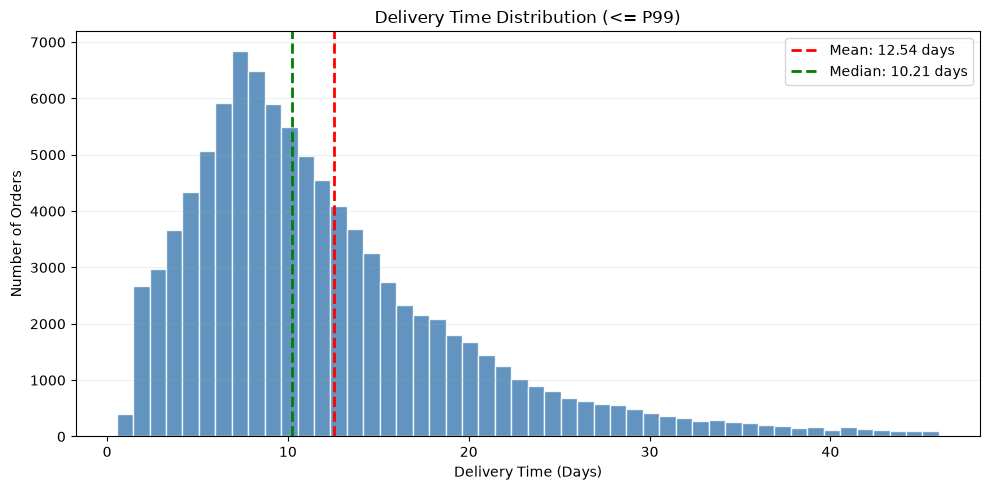

In [3]:
# =========================================================
# 7.3.4 实际配送时间分布可视化
# =========================================================

# 创建图表保存目录
fig_dir = project_root / "reports/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# 提取主要统计指标
delivery_mean = df["delivery_days"].mean()
delivery_median = df["delivery_days"].median()
delivery_p99 = df["delivery_days"].quantile(0.99)

# 为了展示主体分布，仅在绘图时限制到 P99
# 原始数据不删除，后续统计分析仍使用完整数据
plot_data = df.loc[
    df["delivery_days"] <= delivery_p99,
    "delivery_days"
]

plt.figure(figsize=(10, 5))

# 配送时间直方图
plt.hist(
    plot_data,
    bins=50,
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

# 标记均值
plt.axvline(
    delivery_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {delivery_mean:.2f} days"
)

# 标记中位数
plt.axvline(
    delivery_median,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {delivery_median:.2f} days"
)

plt.title("Delivery Time Distribution (<= P99)")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# 保存图表
plt.savefig(
    fig_dir / "delivery_days_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

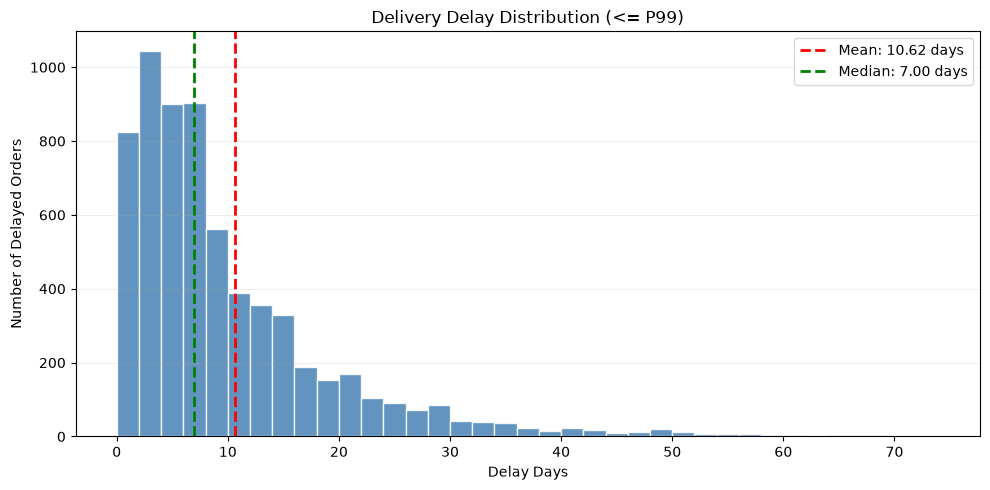

In [4]:
# =========================================================
# 7.3.5 延迟订单的延迟天数分布
# =========================================================

# 只选择延迟订单
delayed_data = df.loc[
    df["is_delayed"] == 1, "delay_days"
].dropna()

# 计算统计指标
delay_mean = delayed_data.mean()
delay_median = delayed_data.median()
delay_p99 = delayed_data.quantile(0.99)

# 仅限制绘图范围，不改变原始数据
plot_data = delayed_data[delayed_data <= delay_p99]

plt.figure(figsize=(10, 5))

plt.hist(
    plot_data,
    bins=np.arange(0, np.ceil(delay_p99) + 3, 2),
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

# 标记均值
plt.axvline(
    delay_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {delay_mean:.2f} days"
)

# 标记中位数
plt.axvline(
    delay_median,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {delay_median:.2f} days"
)

plt.title("Delivery Delay Distribution (<= P99)")
plt.xlabel("Delay Days")
plt.ylabel("Number of Delayed Orders")

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# 保存图表
plt.savefig(
    fig_dir / "delay_days_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

有效评价订单数： 95560

=== 用户评分描述性统计 ===
count    95560.00
mean         4.16
std          1.28
min          1.00
25%          4.00
50%          5.00
75%          5.00
max          5.00
Name: avg_review_score, dtype: float64

=== 评分分组统计 ===
Low (<3): 12222 单，占比 12.79%
Medium (3-4): 7918 单，占比 8.29%
High (>=4): 75420 单，占比 78.92%


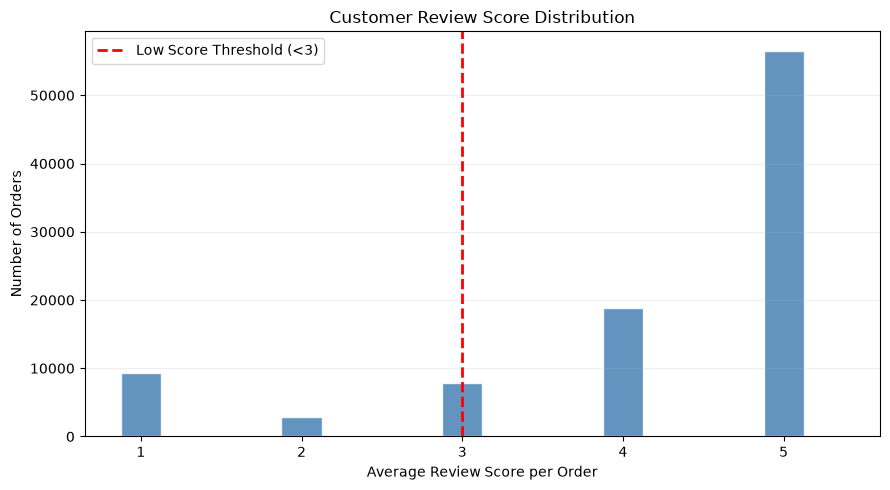

In [5]:
# =========================================================
# 7.3.6 用户评价分布分析
# =========================================================

# 1. 筛选有效评价订单
review_df = df[
    (df["review_count"] > 0)
    & (df["avg_review_score"].notna())
].copy()

print("有效评价订单数：", len(review_df))

# 2. 评分描述性统计
print("\n=== 用户评分描述性统计 ===")

print(
    review_df["avg_review_score"]
    .describe()
    .round(2)
)

# 3. 评价等级划分
# 注意：使用订单平均评分，不进行四舍五入
# 低评分：< 3
# 中等评分：3 <= score < 4
# 高评分：>= 4

review_df["score_group"] = np.select(
    [
        review_df["avg_review_score"] < 3,
        review_df["avg_review_score"] < 4
    ],
    [
        "Low (<3)",
        "Medium (3-4)"
    ],
    default="High (>=4)"
)

score_summary = (
    review_df["score_group"]
    .value_counts()
    .reindex(
        ["Low (<3)", "Medium (3-4)", "High (>=4)"],
        fill_value=0
    )
)

print("\n=== 评分分组统计 ===")

for group, count in score_summary.items():
    percentage = count / len(review_df) * 100
    print(f"{group}: {count} 单，占比 {percentage:.2f}%")

# 4. 绘制评分分布直方图
plt.figure(figsize=(9, 5))

plt.hist(
    review_df["avg_review_score"],
    bins=np.arange(0.875, 5.376, 0.25),
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    3,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Low Score Threshold (<3)"
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Average Review Score per Order")
plt.ylabel("Number of Orders")
plt.xticks([1, 2, 3, 4, 5])

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    fig_dir / "review_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# =========================================================
# 7.4.1 配送延迟与低评分的卡方独立性检验
# =========================================================

# 1. 定义低评分变量
# 订单平均评分 < 3 记为 1，否则为 0
review_df["low_score"] = (
    review_df["avg_review_score"] < 3
).astype(int)

# 2. 构建 2×2 列联表
contingency_table = pd.crosstab(
    review_df["is_delayed"],
    review_df["low_score"]
).reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
)

print("=== 配送状态与低评分列联表 ===")
print(contingency_table)

# 3. Pearson 卡方独立性检验
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table,
    correction=False
)

print("\n=== 卡方检验结果 ===")
print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.6g}")
print(f"自由度: {dof}")
print(f"最小期望频数: {expected.min():.2f}")

# 4. 计算两组低评分率
low_score_rates = (
    contingency_table[1]
    / contingency_table.sum(axis=1)
    * 100
)

print("\n=== 不同配送状态的低评分率 ===")

print(f"准时订单: {low_score_rates.loc[0]:.2f}%")
print(f"延迟订单: {low_score_rates.loc[1]:.2f}%")

# 5. 统计结论
print("\n=== 假设检验结论 ===")

if p_value < 0.05:
    print("拒绝 H0：配送延迟与低评分存在统计显著关联。")
else:
    print("未能拒绝 H0：当前证据不足以证明二者存在关联。")

=== 配送状态与低评分列联表 ===
low_score       0     1
is_delayed             
0           80942  8240
1            2396  3982

=== 卡方检验结果 ===
Chi-square: 15099.9346
p-value: 0
自由度: 1
最小期望频数: 815.74

=== 不同配送状态的低评分率 ===
准时订单: 9.24%
延迟订单: 62.43%

=== 假设检验结论 ===
拒绝 H0：配送延迟与低评分存在统计显著关联。


In [7]:
# =========================================================
# 7.4.2 效应量与 95% 置信区间
# =========================================================

# 1. 从列联表提取数据
# a：延迟且低评分
# b：延迟且非低评分
# c：准时且低评分
# d：准时且非低评分

a = contingency_table.loc[1, 1]
b = contingency_table.loc[1, 0]
c = contingency_table.loc[0, 1]
d = contingency_table.loc[0, 0]

n_delayed = a + b
n_ontime = c + d

p_delayed = a / n_delayed
p_ontime = c / n_ontime

# 95% 置信区间对应的标准正态分位数
z = stats.norm.ppf(0.975)


# 2. 风险差 RD
# 衡量两组低评分率的绝对差异

rd = p_delayed - p_ontime

se_rd = np.sqrt(
    p_delayed * (1 - p_delayed) / n_delayed
    + p_ontime * (1 - p_ontime) / n_ontime
)

rd_ci = (
    rd - z * se_rd,
    rd + z * se_rd
)


# 3. 相对风险 RR
# 衡量延迟组低评分概率是准时组的多少倍

rr = p_delayed / p_ontime

se_log_rr = np.sqrt(
    1/a - 1/n_delayed
    + 1/c - 1/n_ontime
)

rr_ci = (
    np.exp(np.log(rr) - z * se_log_rr),
    np.exp(np.log(rr) + z * se_log_rr)
)


# 4. 优势比 OR
# 后续 Logistic 回归也会使用 OR 解释结果

odds_ratio = (a * d) / (b * c)

se_log_or = np.sqrt(
    1/a + 1/b + 1/c + 1/d
)

or_ci = (
    np.exp(np.log(odds_ratio) - z * se_log_or),
    np.exp(np.log(odds_ratio) + z * se_log_or)
)


# 5. 输出统计结果

print("=== 效应量与95%置信区间 ===")

print(
    f"风险差 RD: {rd*100:.2f} 个百分点 "
    f"[{rd_ci[0]*100:.2f}, {rd_ci[1]*100:.2f}]"
)

print(
    f"相对风险 RR: {rr:.3f} "
    f"[{rr_ci[0]:.3f}, {rr_ci[1]:.3f}]"
)

print(
    f"优势比 OR: {odds_ratio:.3f} "
    f"[{or_ci[0]:.3f}, {or_ci[1]:.3f}]"
)

=== 效应量与95%置信区间 ===
风险差 RD: 53.19 个百分点 [51.99, 54.40]
相对风险 RR: 6.757 [6.570, 6.949]
优势比 OR: 16.325 [15.444, 17.257]


In [8]:
# =========================================================
# 7.4.3 Mann–Whitney U 检验
# 目的：比较准时订单与延迟订单的评分分布
# =========================================================

# 1. 提取两组有效评分
ontime_scores = review_df.loc[
    review_df["is_delayed"] == 0,
    "avg_review_score"
].dropna()

delayed_scores = review_df.loc[
    review_df["is_delayed"] == 1,
    "avg_review_score"
].dropna()


# 2. 描述性统计
print("=== 两组评分统计 ===")

print(
    f"准时订单：n={len(ontime_scores)}, "
    f"均值={ontime_scores.mean():.3f}, "
    f"中位数={ontime_scores.median():.2f}"
)

print(
    f"延迟订单：n={len(delayed_scores)}, "
    f"均值={delayed_scores.mean():.3f}, "
    f"中位数={delayed_scores.median():.2f}"
)


# 3. Mann–Whitney U 检验
# 使用双侧检验及大样本正态近似
# scipy 会对大量相同评分（ties）进行方差校正

u_stat, p_value_mw = stats.mannwhitneyu(
    delayed_scores,
    ontime_scores,
    alternative="two-sided",
    method="asymptotic"
)

print("\n=== Mann–Whitney U 检验 ===")
print(f"U statistic: {u_stat:.2f}")

if p_value_mw < 0.001:
    print("p-value: < 0.001")
else:
    print(f"p-value: {p_value_mw:.6f}")


# 4. 计算秩二列相关系数
# 衡量两组评分的相对排序差异
# 负值表示延迟组评分整体倾向于更低

n1 = len(delayed_scores)
n2 = len(ontime_scores)

rank_biserial = 2 * u_stat / (n1 * n2) - 1

print(f"Rank-biserial correlation: {rank_biserial:.4f}")


# 5. 假设检验结论
print("\n=== 检验结论 ===")

if p_value_mw < 0.05:
    print("拒绝 H0：两组评分分布存在统计显著差异。")
else:
    print("未能拒绝 H0：没有发现显著的评分分布差异。")

=== 两组评分统计 ===
准时订单：n=89182, 均值=4.291, 中位数=5.00
延迟订单：n=6378, 均值=2.272, 中位数=1.00

=== Mann–Whitney U 检验 ===
U statistic: 102904249.00
p-value: < 0.001
Rank-biserial correlation: -0.6382

=== 检验结论 ===
拒绝 H0：两组评分分布存在统计显著差异。


In [9]:
# =========================================================
# 7.5.1 Logistic 回归：基准模型
# 目的：分析配送延迟与订单低评分之间的关联
# =========================================================

import statsmodels.api as sm

# 1. 准备建模数据
# 目标变量：low_score（是否低评分）
# 解释变量：is_delayed（是否延迟）

model_df = review_df[
    ["low_score", "is_delayed"]
].dropna().copy()

print("建模样本量：", len(model_df))


# 2. 构建自变量与因变量

X = model_df[["is_delayed"]]

# 添加截距项
X = sm.add_constant(X)

y = model_df["low_score"]


# 3. 拟合 Logistic 回归模型

logit_model = sm.Logit(y, X)

logit_result = logit_model.fit(disp=False)

print("\n=== Logistic 回归结果 ===")
print(logit_result.summary())


# 4. 提取模型系数与优势比 OR

coef = logit_result.params["is_delayed"]

odds_ratio_logit = np.exp(coef)

# 计算 OR 的 95% 置信区间
conf_int = logit_result.conf_int().loc["is_delayed"]

or_lower = np.exp(conf_int.iloc[0])
or_upper = np.exp(conf_int.iloc[1])

p_value_logit = logit_result.pvalues["is_delayed"]


# 5. 输出关键统计结果

print("\n=== 核心结果 ===")

print(f"回归系数 β1: {coef:.4f}")

print(f"优势比 OR: {odds_ratio_logit:.4f}")

print(
    f"OR 95% CI: "
    f"[{or_lower:.4f}, {or_upper:.4f}]"
)

if p_value_logit < 0.001:
    print("p-value: < 0.001")
else:
    print(f"p-value: {p_value_logit:.6f}")

print(
    f"McFadden Pseudo R²: "
    f"{logit_result.prsquared:.4f}"
)

建模样本量： 95560

=== Logistic 回归结果 ===
                           Logit Regression Results                           
Dep. Variable:              low_score   No. Observations:                95560
Model:                          Logit   Df Residuals:                    95558
Method:                           MLE   Df Model:                            1
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                  0.1326
Time:                        11:34:10   Log-Likelihood:                -31694.
converged:                       True   LL-Null:                       -36540.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.2847      0.012   -197.582      0.000      -2.307      -2.262
is_delayed     2.7927      0.028     98.602      0.000       2.737       2.848

=== 核心结果 ===
回归

In [10]:
# =========================================================
# 7.5.2 控制买家州的 Logistic 回归
# 目的：检验控制地区差异后，配送延迟与低评分的关联
# =========================================================

import statsmodels.formula.api as smf

# 1. 准备建模数据
# 只保留目标变量、延迟标记和买家所在州
region_df = review_df[
    ["low_score", "is_delayed", "customer_state"]
].dropna().copy()

print("建模样本量：", len(region_df))
print("买家州数量：", region_df["customer_state"].nunique())

# 检查各州是否同时存在低评分和非低评分订单
state_check = region_df.groupby("customer_state")["low_score"].agg(
    total="count",
    low="sum"
)
state_check["non_low"] = state_check["total"] - state_check["low"]

print(
    "只有单一评分类别的州数量：",
    ((state_check["low"] == 0) |
     (state_check["non_low"] == 0)).sum()
)


# 2. 在相同样本上重新拟合基准模型
# 目的：避免缺失地区信息造成两个模型的样本不一致
baseline_region_model = smf.logit(
    formula="low_score ~ is_delayed",
    data=region_df
).fit(disp=False)


# 3. 建立地区调整模型
# C(customer_state) 自动把州转换为分类虚拟变量
adjusted_model = smf.logit(
    formula="low_score ~ is_delayed + C(customer_state)",
    data=region_df
).fit(
    disp=False,
    maxiter=200
)

print("\n=== 模型收敛情况 ===")
print(
    "地区调整模型：",
    adjusted_model.mle_retvals["converged"]
)


# 4. 提取两个模型的延迟变量 OR 和置信区间
results = []

for name, model in [
    ("Baseline", baseline_region_model),
    ("State-adjusted", adjusted_model)
]:
    coef = model.params["is_delayed"]
    ci = model.conf_int().loc["is_delayed"]

    results.append({
        "Model": name,
        "OR": np.exp(coef),
        "CI_Lower": np.exp(ci.iloc[0]),
        "CI_Upper": np.exp(ci.iloc[1]),
        "P_Value": model.pvalues["is_delayed"],
        "Pseudo_R2": model.prsquared
    })

comparison_df = pd.DataFrame(results)

print("\n=== Logistic 回归模型对比 ===")
print(comparison_df.round(4).to_string(index=False))

建模样本量： 95560
买家州数量： 27
只有单一评分类别的州数量： 0

=== 模型收敛情况 ===
地区调整模型： True

=== Logistic 回归模型对比 ===
         Model      OR  CI_Lower  CI_Upper  P_Value  Pseudo_R2
      Baseline 16.3253   15.4437   17.2572      0.0     0.1326
State-adjusted 15.6324   14.7762   16.5381      0.0     0.1349


In [11]:
# =========================================================
# 7.5.3.2 读取扩展回归数据并检查
# =========================================================

# 1. 读取数据
regression_path = (
    project_root
    / "data/processed/delivery_review_regression.csv"
)

reg_df = pd.read_csv(regression_path)

# 2. 基础检查
print("=== 数据基础检查 ===")
print("数据形状：", reg_df.shape)
print("唯一订单数：", reg_df["order_id"].nunique())
print("缺失值：")
print(reg_df.isna().sum())

# 3. 商品金额分布
print("\n=== 订单商品金额统计 ===")

print(
    reg_df["order_amount"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(2)
)

# 4. 月份及地区覆盖
print("\n=== 时间与地区覆盖 ===")
print("月份数量：", reg_df["purchase_month"].nunique())
print("地区数量：", reg_df["customer_state"].nunique())

# 5. 核对原有建模样本
print("\n=== 样本核验 ===")
print("样本数量一致：", len(reg_df) == len(review_df))
print(
    "订单集合一致：",
    set(reg_df["order_id"]) == set(review_df["order_id"])
)

=== 数据基础检查 ===
数据形状： (95560, 8)
唯一订单数： 95560
缺失值：
order_id            0
customer_state      0
delivery_days       0
delay_days          0
is_delayed          0
avg_review_score    0
order_amount        0
purchase_month      0
dtype: int64

=== 订单商品金额统计 ===
count    95560.00
mean       136.76
std        207.85
min          0.85
50%         86.00
90%        269.00
95%        399.00
99%        990.00
max      13440.00
Name: order_amount, dtype: float64

=== 时间与地区覆盖 ===
月份数量： 20
地区数量： 27

=== 样本核验 ===
样本数量一致： True
订单集合一致： True


In [12]:
# =========================================================
# 7.5.4 多变量 Logistic 回归
# 目的：控制订单金额、地区与购买月份后，
#       检验配送延迟与低评分是否仍存在显著关联
# =========================================================

# 1. 构建目标变量
# 低评分定义：订单平均评分 < 3

reg_df["low_score"] = (
    reg_df["avg_review_score"] < 3
).astype(int)


# 2. 订单金额对数变换
# 减轻订单金额右偏分布的影响

reg_df["log_order_amount"] = np.log1p(
    reg_df["order_amount"]
)


# 3. 构建多变量 Logistic 回归模型
# C() 表示将分类变量转换为虚拟变量
# 地区和月份各自自动选择一个参照组

full_model = smf.logit(
    formula=(
        "low_score ~ "
        "is_delayed + "
        "log_order_amount + "
        "C(customer_state) + "
        "C(purchase_month)"
    ),
    data=reg_df
)

full_result = full_model.fit(
    disp=False,
    maxiter=200
)


# 4. 检查模型是否收敛

print("=== 模型基本信息 ===")

print("建模样本量：", full_result.nobs)

print(
    "模型是否收敛：",
    full_result.mle_retvals["converged"]
)

print(
    "McFadden Pseudo R²：",
    round(full_result.prsquared, 4)
)


# 5. 提取核心变量统计结果

print("\n=== 核心变量回归结果 ===")

for var in ["is_delayed", "log_order_amount"]:

    coef = full_result.params[var]

    odds_ratio = np.exp(coef)

    ci = full_result.conf_int().loc[var]

    ci_lower = np.exp(ci.iloc[0])
    ci_upper = np.exp(ci.iloc[1])

    p_value = full_result.pvalues[var]

    print(f"\n变量：{var}")

    print(f"回归系数：{coef:.4f}")

    print(f"OR：{odds_ratio:.4f}")

    print(
        f"OR 95% CI："
        f"[{ci_lower:.4f}, {ci_upper:.4f}]"
    )

    print(f"p-value：{p_value:.4g}")


# 6. 对比三个模型
# 前两个模型已经在之前的代码单元完成拟合

models = {
    "Model 1 - Baseline": baseline_region_model,
    "Model 2 - State": adjusted_model,
    "Model 3 - Full": full_result
}

comparison = []

for name, result in models.items():

    coef = result.params["is_delayed"]
    ci = result.conf_int().loc["is_delayed"]

    comparison.append({
        "Model": name,
        "N": int(result.nobs),
        "Delay_OR": np.exp(coef),
        "CI_Lower": np.exp(ci.iloc[0]),
        "CI_Upper": np.exp(ci.iloc[1]),
        "Pseudo_R2": result.prsquared
    })

model_comparison = pd.DataFrame(comparison)

print("\n=== 三个模型对比 ===")

print(
    model_comparison.round(4).to_string(index=False)
)

=== 模型基本信息 ===
建模样本量： 95560
模型是否收敛： True
McFadden Pseudo R²： 0.1404

=== 核心变量回归结果 ===

变量：is_delayed
回归系数：2.6953
OR：14.8098
OR 95% CI：[13.9697, 15.7003]
p-value：0

变量：log_order_amount
回归系数：0.1576
OR：1.1707
OR 95% CI：[1.1447, 1.1973]
p-value：6.68e-43

=== 三个模型对比 ===
             Model     N  Delay_OR  CI_Lower  CI_Upper  Pseudo_R2
Model 1 - Baseline 95560   16.3253   15.4437   17.2572     0.1326
   Model 2 - State 95560   15.6324   14.7762   16.5381     0.1349
    Model 3 - Full 95560   14.8098   13.9697   15.7003     0.1404


In [13]:
# =========================================================
# 7.6.1 低评分阈值敏感性分析
# 目的：
# 改变低评分判定标准，检验配送延迟的关联是否稳定
# =========================================================

# 1. 创建新的低评分变量
# 原标准：平均评分 < 3
# 新标准：平均评分 < 4

robust_df = reg_df.copy()

robust_df["low_score_alt"] = (
    robust_df["avg_review_score"] < 4
).astype(int)


# 2. 重新建立完整 Logistic 回归模型
# 保持解释变量、控制变量及样本不变

robust_model = smf.logit(
    formula=(
        "low_score_alt ~ "
        "is_delayed + "
        "log_order_amount + "
        "C(customer_state) + "
        "C(purchase_month)"
    ),
    data=robust_df
)

robust_result = robust_model.fit(
    disp=False,
    maxiter=200
)


# 3. 提取配送延迟变量的统计结果

coef = robust_result.params["is_delayed"]

robust_or = np.exp(coef)

ci = robust_result.conf_int().loc["is_delayed"]

robust_ci_lower = np.exp(ci.iloc[0])
robust_ci_upper = np.exp(ci.iloc[1])

robust_p = robust_result.pvalues["is_delayed"]


# 4. 输出新模型结果

print("=== 阈值敏感性分析 ===")

print("建模样本量：", int(robust_result.nobs))

print(
    "模型是否收敛：",
    robust_result.mle_retvals["converged"]
)

print(f"调整后 OR：{robust_or:.4f}")

print(
    f"OR 95% CI："
    f"[{robust_ci_lower:.4f}, {robust_ci_upper:.4f}]"
)

print(f"p-value：{robust_p:.4g}")


# 5. 对比两种评分阈值

threshold_comparison = pd.DataFrame([
    {
        "Threshold": "Score < 3",
        "OR": np.exp(full_result.params["is_delayed"]),
        "P_Value": full_result.pvalues["is_delayed"]
    },
    {
        "Threshold": "Score < 4",
        "OR": robust_or,
        "P_Value": robust_p
    }
])

print("\n=== 阈值对比 ===")

print(
    threshold_comparison.round(4).to_string(index=False)
)


# 6. 查看不同阈值下两组低评分率

print("\n=== 不同阈值下的低评分率 ===")

for threshold in [3, 4]:

    rates = robust_df.groupby("is_delayed")[
        "avg_review_score"
    ].apply(
        lambda scores: (scores < threshold).mean() * 100
    )

    print(f"\n评分 < {threshold}")

    print(f"准时订单：{rates.loc[0]:.2f}%")
    print(f"延迟订单：{rates.loc[1]:.2f}%")

=== 阈值敏感性分析 ===
建模样本量： 95560
模型是否收敛： True
调整后 OR：11.8638
OR 95% CI：[11.1742, 12.5959]
p-value：0

=== 阈值对比 ===
Threshold      OR  P_Value
Score < 3 14.8098      0.0
Score < 4 11.8638      0.0

=== 不同阈值下的低评分率 ===

评分 < 3
准时订单：9.24%
延迟订单：62.43%

评分 < 4
准时订单：17.34%
延迟订单：73.27%


In [14]:
# =========================================================
# 7.6.2 极端配送订单敏感性分析
# 目的：
# 排除配送时间最长的约 1% 订单，
# 检查配送延迟与低评分的关联是否稳定
# =========================================================

# 1. 计算当前回归样本的配送时间 P99
delivery_p99 = reg_df["delivery_days"].quantile(0.99)

print(f"配送时间 P99：{delivery_p99:.2f} 天")


# 2. 排除配送时间超过 P99 的订单
# 注意：仅调整本次模型样本，不修改原始数据

trimmed_df = reg_df[
    reg_df["delivery_days"] <= delivery_p99
].copy()

print("\n=== 样本变化 ===")

print("原始样本量：", len(reg_df))
print("筛选后样本量：", len(trimmed_df))
print("排除订单数：", len(reg_df) - len(trimmed_df))

print(
    "排除比例：",
    f"{(1 - len(trimmed_df) / len(reg_df)) * 100:.2f}%"
)


# 3. 使用相同变量重新拟合 Logistic 回归

trimmed_model = smf.logit(
    formula=(
        "low_score ~ "
        "is_delayed + "
        "log_order_amount + "
        "C(customer_state) + "
        "C(purchase_month)"
    ),
    data=trimmed_df
)

trimmed_result = trimmed_model.fit(
    disp=False,
    maxiter=200
)


# 4. 提取配送延迟变量的统计结果

coef = trimmed_result.params["is_delayed"]

trimmed_or = np.exp(coef)

ci = trimmed_result.conf_int().loc["is_delayed"]

trimmed_ci_lower = np.exp(ci.iloc[0])
trimmed_ci_upper = np.exp(ci.iloc[1])

trimmed_p = trimmed_result.pvalues["is_delayed"]


# 5. 输出敏感性分析结果

print("\n=== 极端订单敏感性分析 ===")

print("模型是否收敛：", trimmed_result.mle_retvals["converged"])

print(f"调整后 OR：{trimmed_or:.4f}")

print(
    f"OR 95% CI："
    f"[{trimmed_ci_lower:.4f}, {trimmed_ci_upper:.4f}]"
)

if trimmed_p < 0.001:
    print("p-value：< 0.001")
else:
    print(f"p-value：{trimmed_p:.6f}")


# 6. 与原完整模型进行比较

extreme_comparison = pd.DataFrame([
    {
        "Model": "Full Sample",
        "N": int(full_result.nobs),
        "OR": np.exp(full_result.params["is_delayed"]),
        "Pseudo_R2": full_result.prsquared
    },
    {
        "Model": "Exclude >P99",
        "N": int(trimmed_result.nobs),
        "OR": trimmed_or,
        "Pseudo_R2": trimmed_result.prsquared
    }
])

print("\n=== 模型对比 ===")

print(
    extreme_comparison.round(4).to_string(index=False)
)

配送时间 P99：45.82 天

=== 样本变化 ===
原始样本量： 95560
筛选后样本量： 94604
排除订单数： 956
排除比例： 1.00%

=== 极端订单敏感性分析 ===
模型是否收敛： True
调整后 OR：13.5000
OR 95% CI：[12.6954, 14.3556]
p-value：< 0.001

=== 模型对比 ===
       Model     N      OR  Pseudo_R2
 Full Sample 95560 14.8098     0.1404
Exclude >P99 94604 13.5000     0.1176


=== 模型结果汇总 ===
            Model      OR   Lower   Upper
0        Baseline  16.325  15.444  17.257
1  State-adjusted  15.632  14.776  16.538
2   Full-adjusted  14.810  13.970  15.700
3    Exclude >P99  13.500  12.695  14.356


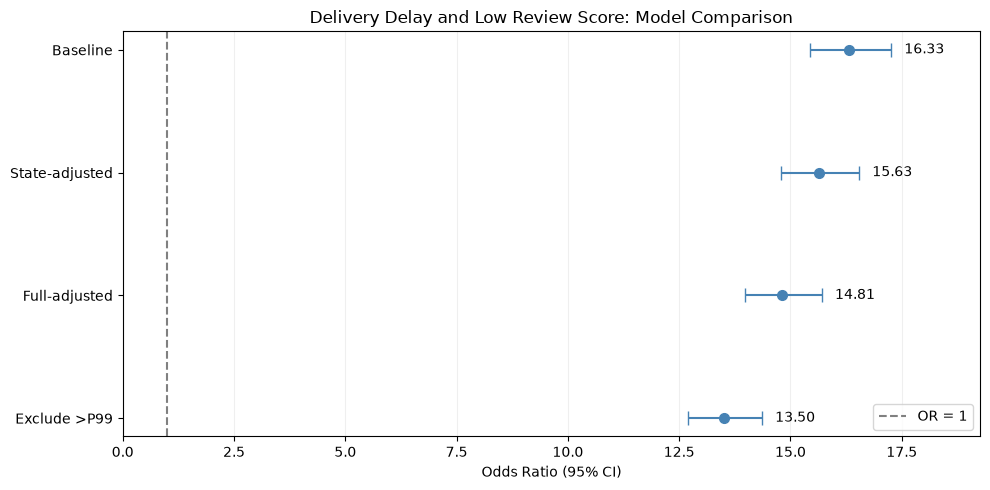

In [15]:
# =========================================================
# 7.7.1 Logistic 回归结果森林图
# 目的：比较不同模型中配送延迟的 OR 及其置信区间
# =========================================================

# 1. 汇总模型结果
model_results = {
    "Baseline": baseline_region_model,
    "State-adjusted": adjusted_model,
    "Full-adjusted": full_result,
    "Exclude >P99": trimmed_result
}

plot_rows = []

for name, result in model_results.items():

    coef = result.params["is_delayed"]
    ci = result.conf_int().loc["is_delayed"]

    plot_rows.append({
        "Model": name,
        "OR": np.exp(coef),
        "Lower": np.exp(ci.iloc[0]),
        "Upper": np.exp(ci.iloc[1])
    })

forest_df = pd.DataFrame(plot_rows)

print("=== 模型结果汇总 ===")
print(forest_df.round(3))


# 2. 绘制森林图
fig, ax = plt.subplots(figsize=(10, 5))

y_positions = np.arange(len(forest_df))

# 绘制 OR 和置信区间
ax.errorbar(
    forest_df["OR"],
    y_positions,
    xerr=[
        forest_df["OR"] - forest_df["Lower"],
        forest_df["Upper"] - forest_df["OR"]
    ],
    fmt="o",
    color="steelblue",
    ecolor="steelblue",
    capsize=5,
    markersize=7
)

# OR = 1 表示无关联的参考线
ax.axvline(
    1,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="OR = 1"
)

# 标记具体 OR 数值
for i, row in forest_df.iterrows():
    ax.text(
        row["Upper"] + 0.3,
        i,
        f'{row["OR"]:.2f}',
        va="center",
        fontsize=10
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(forest_df["Model"])

ax.invert_yaxis()

ax.set_xlabel("Odds Ratio (95% CI)")
ax.set_title("Delivery Delay and Low Review Score: Model Comparison")

ax.set_xlim(0, forest_df["Upper"].max() + 2)

ax.grid(axis="x", alpha=0.2)
ax.legend()

plt.tight_layout()

# 3. 保存图表
plt.savefig(
    fig_dir / "logistic_or_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()